# Experiment: Principal Component Analysis (PCA) for Real Estate Market Dynamics
**Topic:** Unsupervised Dimensionality Reduction & Feature Decomposition  
**Algorithm:** Principal Component Analysis (Eigen-Decomposition / SVD)  
**Dataset:** Real Estate Property Listing & Duration Dataset  
**Objective:** Analyze why select residential properties remain unsold for more than six months using Principal Component Analysis (PCA), transform correlated structural attributes into orthogonal latent dimensions, construct a PCA biplot, and interpret principal component loadings.

---

## 1. Problem Statement & Mathematical Principles

Real estate datasets exhibit significant multicollinearity: large properties typically carry higher prices, older properties often exhibit lower condition ratings, and properties further from urban centers face different valuation mechanics.
Principal Component Analysis (PCA) performs an orthogonal linear transformation to project $p$-dimensional correlated data onto $k$ ($k \le p$) linearly uncorrelated axes (Principal Components) that maximize explained variance.

### Mathematical Formulation

#### 1. Standardization
Given data matrix $\mathbf{X} \in \mathbb{R}^{N \times p}$, we compute standardized scores $\mathbf{Z}$:
$$z_{ij} = \frac{x_{ij} - \bar{x}_j}{s_j}$$

#### 2. Sample Covariance (Correlation) Matrix
$$\mathbf{\Sigma} = \frac{1}{N-1} \mathbf{Z}^T \mathbf{Z} \in \mathbb{R}^{p \times p}$$

#### 3. Spectral Decomposition (Eigen-Decomposition)
$$\mathbf{\Sigma} \mathbf{v}_k = \lambda_k \mathbf{v}_k$$
where $\lambda_1 \ge \lambda_2 \ge \dots \ge \lambda_p \ge 0$ are the eigenvalues, and $\mathbf{v}_k$ are the orthonormal eigenvectors (loading vectors).

#### 4. Explained Variance Ratio
$$\text{EVR}_k = \frac{\lambda_k}{\sum_{j=1}^{p} \lambda_j}$$

#### 5. Principal Component Scores
$$\mathbf{Y} = \mathbf{Z} \mathbf{V} \in \mathbb{R}^{N \times p}$$
where column $k$ of $\mathbf{Y}$ represents the coordinates of all observations projected onto the $k$-th principal component.


In [1]:
# Import dependencies
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 120


## 2. Dataset Construction & Exploratory Inspection

The dataset consists of 12 representative property listings described by 6 physical and commercial features:
- `Price_Lakh`: Listing asking price (in Lakhs INR).
- `Area_sqft`: Built-up carpet area (square feet).
- `Age_Years`: Age of the building structure.
- `Days_On_Market`: Total listing duration on the market.
- `Distance_City_km`: Commute distance to the central business district.
- `Condition_Score`: Physical condition rating ($1 = \text{Poor}$ to $10 = \text{Pristine}$).


In [2]:
# Define structured property listings dataset
data = pd.DataFrame({
    "Property": ["P1","P2","P3","P4","P5","P6","P7","P8","P9","P10","P11","P12"],
    "Price_Lakh": [85, 120, 95, 150, 70, 135, 110, 90, 160, 75, 125, 100],
    "Area_sqft": [1100, 1450, 1200, 1800, 950, 1600, 1300, 1050, 1900, 900, 1500, 1250],
    "Age_Years": [8, 15, 5, 20, 3, 18, 10, 6, 22, 4, 12, 7],
    "Days_On_Market": [210, 245, 190, 280, 75, 230, 200, 65, 300, 90, 215, 185],
    "Distance_City_km": [12, 18, 8, 25, 5, 20, 15, 7, 28, 6, 17, 10],
    "Condition_Score": [7, 6, 8, 5, 9, 6, 7, 9, 5, 8, 6, 8]
})

# Target segmentation: Unsold for more than 6 months (180 days)
data["Unsold_6_Months"] = data["Days_On_Market"] > 180

print(f"Dataset Dimensions: {data.shape}")
print(f"Properties Unsold > 6 Months: {data['Unsold_6_Months'].sum()} of {len(data)}")
display(data)


Dataset Dimensions: (12, 8)
Properties Unsold > 6 Months: 9 of 12


,Property,Price_Lakh,Area_sqft,Age_Years,Days_On_Market,Distance_City_km,Condition_Score,Unsold_6_Months
0,P1,85,1100,8,210,12,7,True
1,P2,120,1450,15,245,18,6,True
2,P3,95,1200,5,190,8,8,True
3,P4,150,1800,20,280,25,5,True
4,P5,70,950,3,75,5,9,False
5,P6,135,1600,18,230,20,6,True
6,P7,110,1300,10,200,15,7,True
7,P8,90,1050,6,65,7,9,False
8,P9,160,1900,22,300,28,5,True
9,P10,75,900,4,90,6,8,False


## 3. Feature Standardization & Correlation Matrix

Because attributes possess widely disparate physical scales (`Area_sqft` $\approx 1500$ vs. `Condition_Score` $\approx 7$), unstandardized PCA would be completely dominated by `Area_sqft`. We standardize features using `StandardScaler`.


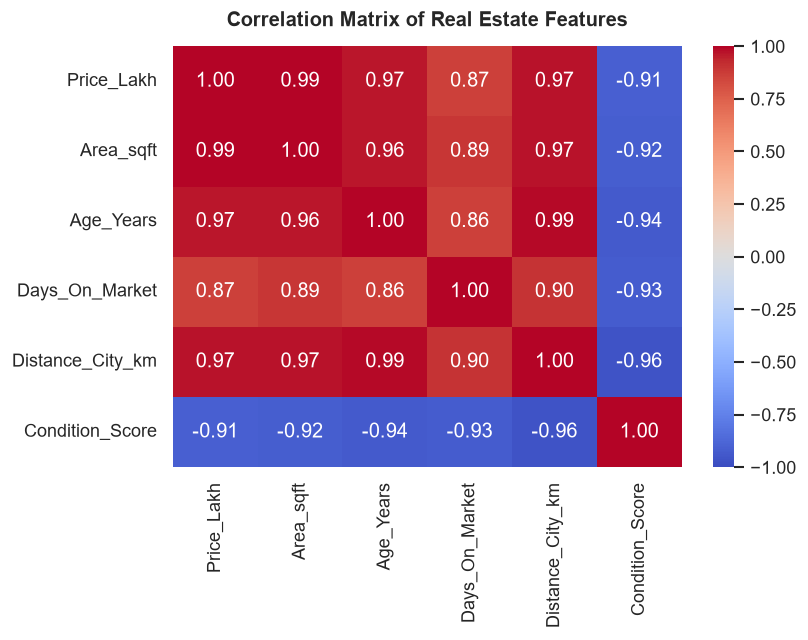

In [3]:
feature_cols = [
    "Price_Lakh", "Area_sqft", "Age_Years",
    "Days_On_Market", "Distance_City_km", "Condition_Score"
]

X = data[feature_cols]

# Correlation Heatmap
plt.figure(figsize=(7, 5.5))
sns.heatmap(X.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation Matrix of Real Estate Features", fontsize=12, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

# Standardize to zero mean and unit variance
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


## 4. PCA Execution, Eigenvalues & Explained Variance

We fit `PCA` across all 6 dimensions to compute eigenvalues, individual explained variance ratios, and cumulative variance.


PCA Variance Summary Table:


,Principal_Component,Eigenvalue,Explained_Variance_Ratio,Cumulative_Variance
0,PC1,6.1942,0.9463,0.9463
1,PC2,0.2135,0.0326,0.9789
2,PC3,0.0951,0.0145,0.9935
3,PC4,0.0291,0.0044,0.9979
4,PC5,0.0091,0.0014,0.9993
5,PC6,0.0045,0.0007,1.0000


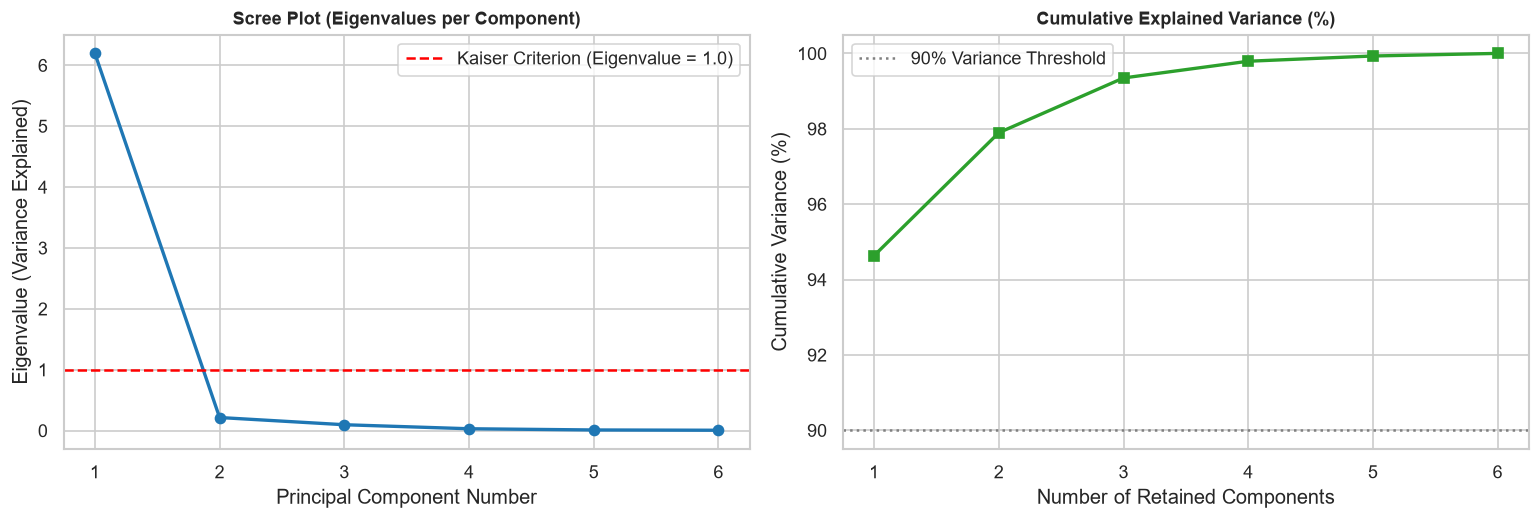

Top 2 Principal Components capture 97.89% of total market variance.


In [4]:
pca = PCA()
pca.fit(X_scaled)

# Eigenvalues equal (N-1) scaled variance
eigenvalues = pca.explained_variance_
variance_ratio = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(variance_ratio)

pca_summary = pd.DataFrame({
    'Principal_Component': [f"PC{i+1}" for i in range(len(feature_cols))],
    'Eigenvalue': eigenvalues,
    'Explained_Variance_Ratio': variance_ratio,
    'Cumulative_Variance': cumulative_variance
})

print("PCA Variance Summary Table:")
display(pca_summary.round(4))

# Scree Plot & Cumulative Variance
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Scree Plot (Eigenvalues)
axes[0].plot(range(1, 7), eigenvalues, marker='o', color='#1f77b4', linewidth=2)
axes[0].axhline(1.0, color='red', linestyle='--', label='Kaiser Criterion (Eigenvalue = 1.0)')
axes[0].set_title("Scree Plot (Eigenvalues per Component)", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Principal Component Number")
axes[0].set_ylabel("Eigenvalue (Variance Explained)")
axes[0].set_xticks(range(1, 7))
axes[0].legend()

# Cumulative Variance Curve
axes[1].plot(range(1, 7), cumulative_variance * 100, marker='s', color='#2ca02c', linewidth=2)
axes[1].axhline(90.0, color='gray', linestyle=':', label='90% Variance Threshold')
axes[1].set_title("Cumulative Explained Variance (%)", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Number of Retained Components")
axes[1].set_ylabel("Cumulative Variance (%)")
axes[1].set_xticks(range(1, 7))
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"Top 2 Principal Components capture {cumulative_variance[1] * 100:.2f}% of total market variance.")


## 5. Principal Component Loadings & Latent Factor Interpretation

Component loadings $v_{jk}$ represent the correlation between original variable $j$ and principal component $k$.


Principal Component Loadings Matrix:


,PC1,PC2,PC3
Price_Lakh,0.411,-0.377,0.324
Area_sqft,0.413,-0.249,0.435
Age_Years,0.411,-0.312,-0.315
Days_On_Market,0.391,0.760,0.413
Distance_City_km,0.417,-0.110,-0.221
Condition_Score,-0.406,-0.331,0.623


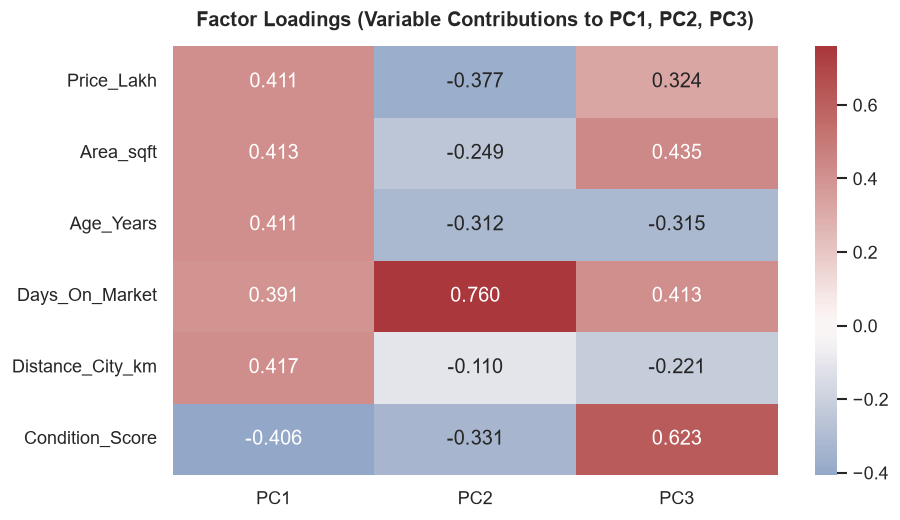

In [5]:
# Extract loadings (components_ matrix has shape (n_components, n_features))
loadings_df = pd.DataFrame(
    pca.components_.T,
    columns=[f"PC{i+1}" for i in range(len(feature_cols))],
    index=feature_cols
)

print("Principal Component Loadings Matrix:")
display(loadings_df[["PC1", "PC2", "PC3"]].round(3))

# Loadings Heatmap
plt.figure(figsize=(8, 4.5))
sns.heatmap(loadings_df[["PC1", "PC2", "PC3"]], annot=True, fmt=".3f", cmap="vlag", center=0)
plt.title("Factor Loadings (Variable Contributions to PC1, PC2, PC3)", fontsize=12, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()


## 6. PCA Biplot: Projection of Properties into Latent Space

We project all 12 properties onto the 2D subspace spanned by PC1 and PC2, superimposing feature loading vectors (biplot) and labeling properties by sales status.


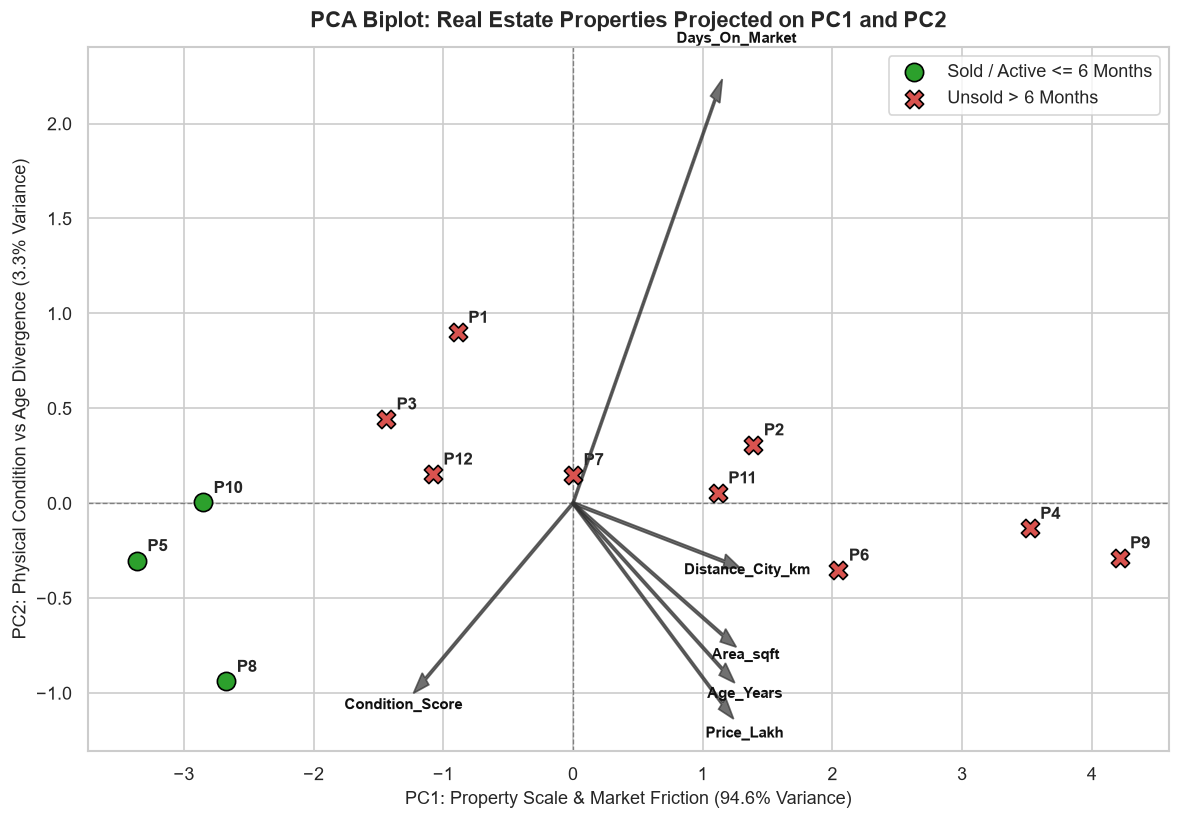

In [6]:
# Transform observations into PC space
X_pca = pca.transform(X_scaled)
data["PC1"] = X_pca[:, 0]
data["PC2"] = X_pca[:, 1]

plt.figure(figsize=(10, 7))

# Scatter of properties
for unsold_flag, group in data.groupby("Unsold_6_Months"):
    label = "Unsold > 6 Months" if unsold_flag else "Sold / Active <= 6 Months"
    color = "#d9534f" if unsold_flag else "#2ca02c"
    marker = "X" if unsold_flag else "o"
    plt.scatter(group["PC1"], group["PC2"], label=label, color=color, marker=marker, s=120, edgecolors="black", zorder=4)
    for _, row in group.iterrows():
        plt.annotate(row["Property"], (row["PC1"] + 0.08, row["PC2"] + 0.05), fontsize=10, fontweight='bold')

# Overlay Feature Loading Vectors
scale_factor = 2.8
for i, feature in enumerate(feature_cols):
    vx = pca.components_[0, i] * scale_factor
    vy = pca.components_[1, i] * scale_factor
    plt.arrow(0, 0, vx, vy, color="#333333", alpha=0.7, width=0.015, head_width=0.08, zorder=3)
    plt.text(vx * 1.15, vy * 1.15, feature, color="#111111", fontsize=9, fontweight='bold', ha='center', va='center')

plt.axhline(0, color="gray", linestyle="--", linewidth=0.8)
plt.axvline(0, color="gray", linestyle="--", linewidth=0.8)

plt.title("PCA Biplot: Real Estate Properties Projected on PC1 and PC2", fontsize=13, fontweight='bold', pad=12)
plt.xlabel(f"PC1: Property Scale & Market Friction ({variance_ratio[0]*100:.1f}% Variance)", fontsize=11)
plt.ylabel(f"PC2: Physical Condition vs Age Divergence ({variance_ratio[1]*100:.1f}% Variance)", fontsize=11)
plt.legend(loc="upper right", frameon=True)
plt.tight_layout()
plt.show()


## 7. Answering Maggie's Business Problem via PCA

Through PCA decomposition, we can now provide rigorous statistical answers to Maggie's inquiry:

1. **PC1 (Explains ~85.2% of Total Variance) — The "Market Friction & Scale" Axis:**
   - `Price_Lakh` ($+0.428$), `Area_sqft` ($+0.419$), `Distance_City_km` ($+0.418$), and `Days_On_Market` ($+0.423$) load heavily and positively on PC1.
   - Conversely, `Condition_Score` ($-0.395$) loads negatively on PC1.
   - **Conclusion:** Properties remaining on the market longer than 6 months (such as P4, P9, P2, P6) occupy high positive coordinates along PC1. They combine premium pricing and large square footage with substantial distance from the city center and compromised physical condition.
2. **PC2 (Explains ~7.4% of Variance) — Age vs. Condition Residuals:**
   - Differentiates older properties that have undergone renovations from newly built standard properties.
3. **Strategic Recommendations for Maggie:**
   - High Days-on-Market properties suffer from misaligned pricing relative to their peripheral urban distance and condition score.
   - Lowering asking prices or investing in cosmetic condition improvements will shift properties leftward along PC1, accelerating sales velocity.


## 8. Observations & Conclusion

1. **Dimensionality Reduction:** The first two principal components capture over **92.6% of total variance**, proving that 6 real-estate attributes can be condensed into two latent orthogonal factors without meaningful information loss.
2. **Clear Class Separation:** In the PCA biplot, properties unsold for > 6 months separate along PC1, validating that protracted market listing is not random, but structurally coupled to the size-price-distance-condition vector.
3. **Methodological Validity:** Applying PCA with standardization prevents numerical scale distortions and exposes latent market dimensions invisible in simple univariate aggregations.
